In [ ]:
import pandas as pd
import numpy as np
import seaborn as sns
from sklearn.preprocessing import StandardScaler,LabelEncoder,OneHotEncoder,OrdinalEncoder
import warnings
import matplotlib.pyplot as plt
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import FunctionTransformer
import pickle
from sklearn.pipeline import Pipeline

In [ ]:
df=pd.read_csv("/content/complex_credit_card_fraud.csv")
df

,Transaction_ID,Customer_ID,Txn_Hour,Txn_Day_of_Week,Is_Weekend,Cardholder_Age,Card_Type,Credit_Limit,Annual_Income,Transactions_Last_24h,Declined_Transactions_Last_24h,Historical_Fraud_Alerts,Merchant_Category,Amount,Is_International,Online_Transaction,Location_Mismatch,Device_Trust_Score,VPN_Detected,Is_Fraud
0,TXN_10000000,CUST_1860,7,5,1,40,Mastercard_Standard,1000,14272,4,0,0,restaurants,8.64,0,1,0,65,0,0
1,TXN_10000001,CUST_6390,12,5,1,82,Mastercard_Platinum,25000,162828,2,0,0,services,11.25,0,1,0,52,0,0
2,TXN_10000002,CUST_6226,16,0,0,24,Visa_Gold,10000,62673,3,1,0,online_shopping,61.14,1,1,0,21,0,0
3,TXN_10000003,CUST_6191,23,3,0,23,Mastercard_Standard,1000,21056,3,0,0,online_shopping,4.79,0,1,0,90,0,0
4,TXN_10000004,CUST_4772,23,1,0,82,Mastercard_Platinum,10000,58085,1,0,0,restaurants,4.67,0,0,0,93,0,0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
99995,TXN_10099995,CUST_7297,6,3,0,54,Visa_Gold,10000,82075,3,0,0,online_shopping,92.38,0,1,0,10,0,0
99996,TXN_10099996,CUST_7567,18,1,0,59,Mastercard_Standard,10000,50733,4,1,0,services,17.73,0,1,0,75,0,0
99997,TXN_10099997,CUST_5743,22,0,0,42,Mastercard_Standard,5000,45475,6,0,0,services,12.38,0,0,0,29,1,0
99998,TXN_10099998,CUST_1291,14,2,0,58,Amex_Gold,5000,43351,2,0,0,restaurants,14.39,0,1,0,92,0,0


In [ ]:
df.head()

,Transaction_ID,Customer_ID,Txn_Hour,Txn_Day_of_Week,Is_Weekend,Cardholder_Age,Card_Type,Credit_Limit,Annual_Income,Transactions_Last_24h,Declined_Transactions_Last_24h,Historical_Fraud_Alerts,Merchant_Category,Amount,Is_International,Online_Transaction,Location_Mismatch,Device_Trust_Score,VPN_Detected,Is_Fraud
0,TXN_10000000,CUST_1860,7,5,1,40,Mastercard_Standard,1000,14272,4,0,0,restaurants,8.64,0,1,0,65,0,0
1,TXN_10000001,CUST_6390,12,5,1,82,Mastercard_Platinum,25000,162828,2,0,0,services,11.25,0,1,0,52,0,0
2,TXN_10000002,CUST_6226,16,0,0,24,Visa_Gold,10000,62673,3,1,0,online_shopping,61.14,1,1,0,21,0,0
3,TXN_10000003,CUST_6191,23,3,0,23,Mastercard_Standard,1000,21056,3,0,0,online_shopping,4.79,0,1,0,90,0,0
4,TXN_10000004,CUST_4772,23,1,0,82,Mastercard_Platinum,10000,58085,1,0,0,restaurants,4.67,0,0,0,93,0,0


In [ ]:
df.tail()

,Transaction_ID,Customer_ID,Txn_Hour,Txn_Day_of_Week,Is_Weekend,Cardholder_Age,Card_Type,Credit_Limit,Annual_Income,Transactions_Last_24h,Declined_Transactions_Last_24h,Historical_Fraud_Alerts,Merchant_Category,Amount,Is_International,Online_Transaction,Location_Mismatch,Device_Trust_Score,VPN_Detected,Is_Fraud
99995,TXN_10099995,CUST_7297,6,3,0,54,Visa_Gold,10000,82075,3,0,0,online_shopping,92.38,0,1,0,10,0,0
99996,TXN_10099996,CUST_7567,18,1,0,59,Mastercard_Standard,10000,50733,4,1,0,services,17.73,0,1,0,75,0,0
99997,TXN_10099997,CUST_5743,22,0,0,42,Mastercard_Standard,5000,45475,6,0,0,services,12.38,0,0,0,29,1,0
99998,TXN_10099998,CUST_1291,14,2,0,58,Amex_Gold,5000,43351,2,0,0,restaurants,14.39,0,1,0,92,0,0
99999,TXN_10099999,CUST_2433,11,6,1,45,Amex_Gold,5000,41380,6,0,0,grocery,43.29,1,1,0,21,0,0


In [ ]:
df.describe()

,Txn_Hour,Txn_Day_of_Week,Is_Weekend,Cardholder_Age,Credit_Limit,Annual_Income,Transactions_Last_24h,Declined_Transactions_Last_24h,Historical_Fraud_Alerts,Amount,Is_International,Online_Transaction,Location_Mismatch,Device_Trust_Score,VPN_Detected,Is_Fraud
count,100000.000000,100000.000000,100000.000000,100000.000000,100000.000000,100000.000000,100000.000000,100000.000000,100000.000000,100000.000000,100000.00000,100000.000000,100000.000000,100000.000000,100000.000000,100000.000000
mean,11.475020,3.034760,0.265520,51.044120,7280.480000,55090.343590,3.494310,0.150560,0.063380,65.581357,0.05992,0.546820,0.030540,54.936760,0.040210,0.004170
std,6.921183,1.938951,0.441612,19.347713,8744.075455,51104.538429,1.581484,0.387264,0.297597,198.825642,0.23734,0.497806,0.172069,25.990826,0.196452,0.064441
min,0.000000,0.000000,0.000000,18.000000,1000.000000,12000.000000,1.000000,0.000000,0.000000,0.430000,0.00000,0.000000,0.000000,10.000000,0.000000,0.000000
25%,5.000000,1.000000,0.000000,34.000000,1000.000000,25123.750000,2.000000,0.000000,0.000000,13.347500,0.00000,0.000000,0.000000,32.000000,0.000000,0.000000
50%,11.000000,3.000000,0.000000,51.000000,5000.000000,42295.000000,3.000000,0.000000,0.000000,27.140000,0.00000,1.000000,0.000000,55.000000,0.000000,0.000000
75%,17.000000,5.000000,1.000000,68.000000,10000.000000,59331.500000,4.000000,0.000000,0.000000,58.092500,0.00000,1.000000,0.000000,77.000000,0.000000,0.000000
max,23.000000,6.000000,1.000000,84.000000,50000.000000,425651.000000,13.000000,3.000000,3.000000,23076.850000,1.00000,1.000000,1.000000,100.000000,1.000000,1.000000


In [ ]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 100000 entries, 0 to 99999
Data columns (total 20 columns):
 #   Column                          Non-Null Count   Dtype  
---  ------                          --------------   -----  
 0   Transaction_ID                  100000 non-null  object 
 1   Customer_ID                     100000 non-null  object 
 2   Txn_Hour                        100000 non-null  int64  
 3   Txn_Day_of_Week                 100000 non-null  int64  
 4   Is_Weekend                      100000 non-null  int64  
 5   Cardholder_Age                  100000 non-null  int64  
 6   Card_Type                       100000 non-null  object 
 7   Credit_Limit                    100000 non-null  int64  
 8   Annual_Income                   100000 non-null  int64  
 9   Transactions_Last_24h           100000 non-null  int64  
 10  Declined_Transactions_Last_24h  100000 non-null  int64  
 11  Historical_Fraud_Alerts         100000 non-null  int64  
 12  Merchant_Category

In [ ]:
df.shape

(100000, 20)

In [ ]:
numerical_cols = df.select_dtypes(include=['int', 'float']).columns

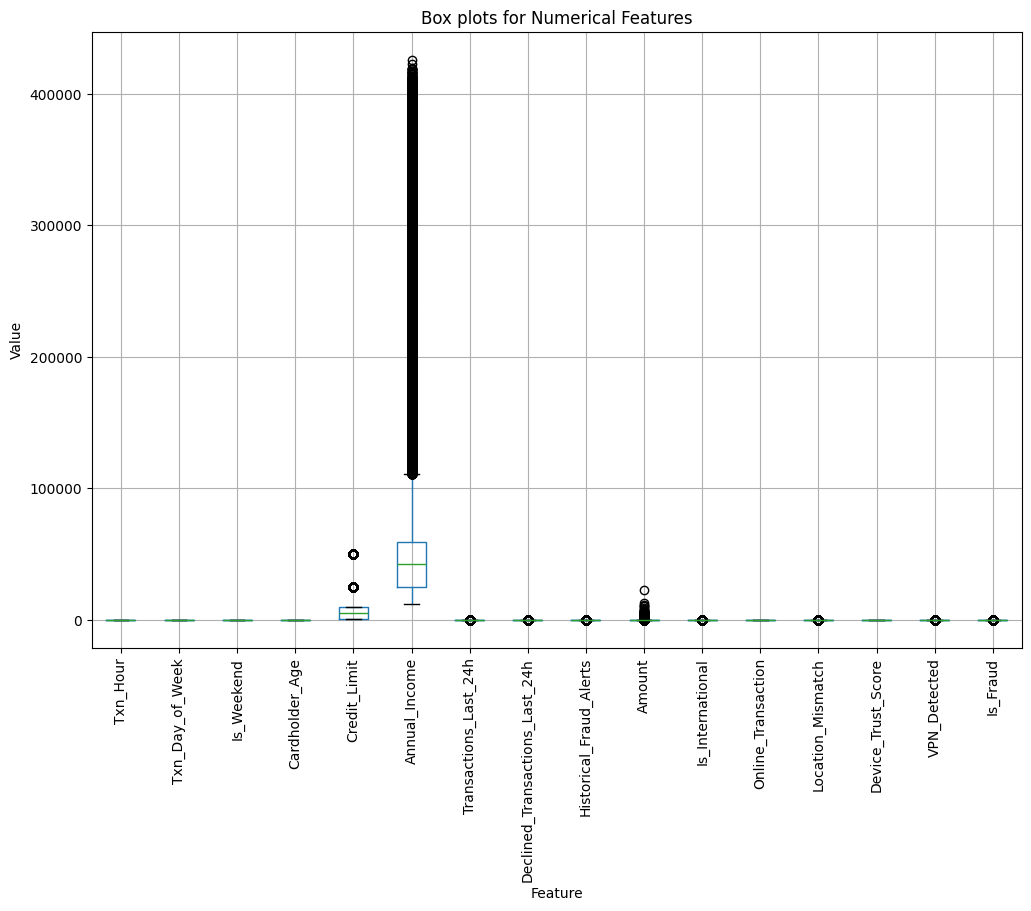

In [ ]:
plt.figure(figsize=(12, 8))
df[numerical_cols].boxplot()
plt.xticks(rotation=90)
plt.title('Box plots for Numerical Features')
plt.ylabel('Value')
plt.xlabel('Feature')
plt.show()

<Axes: >

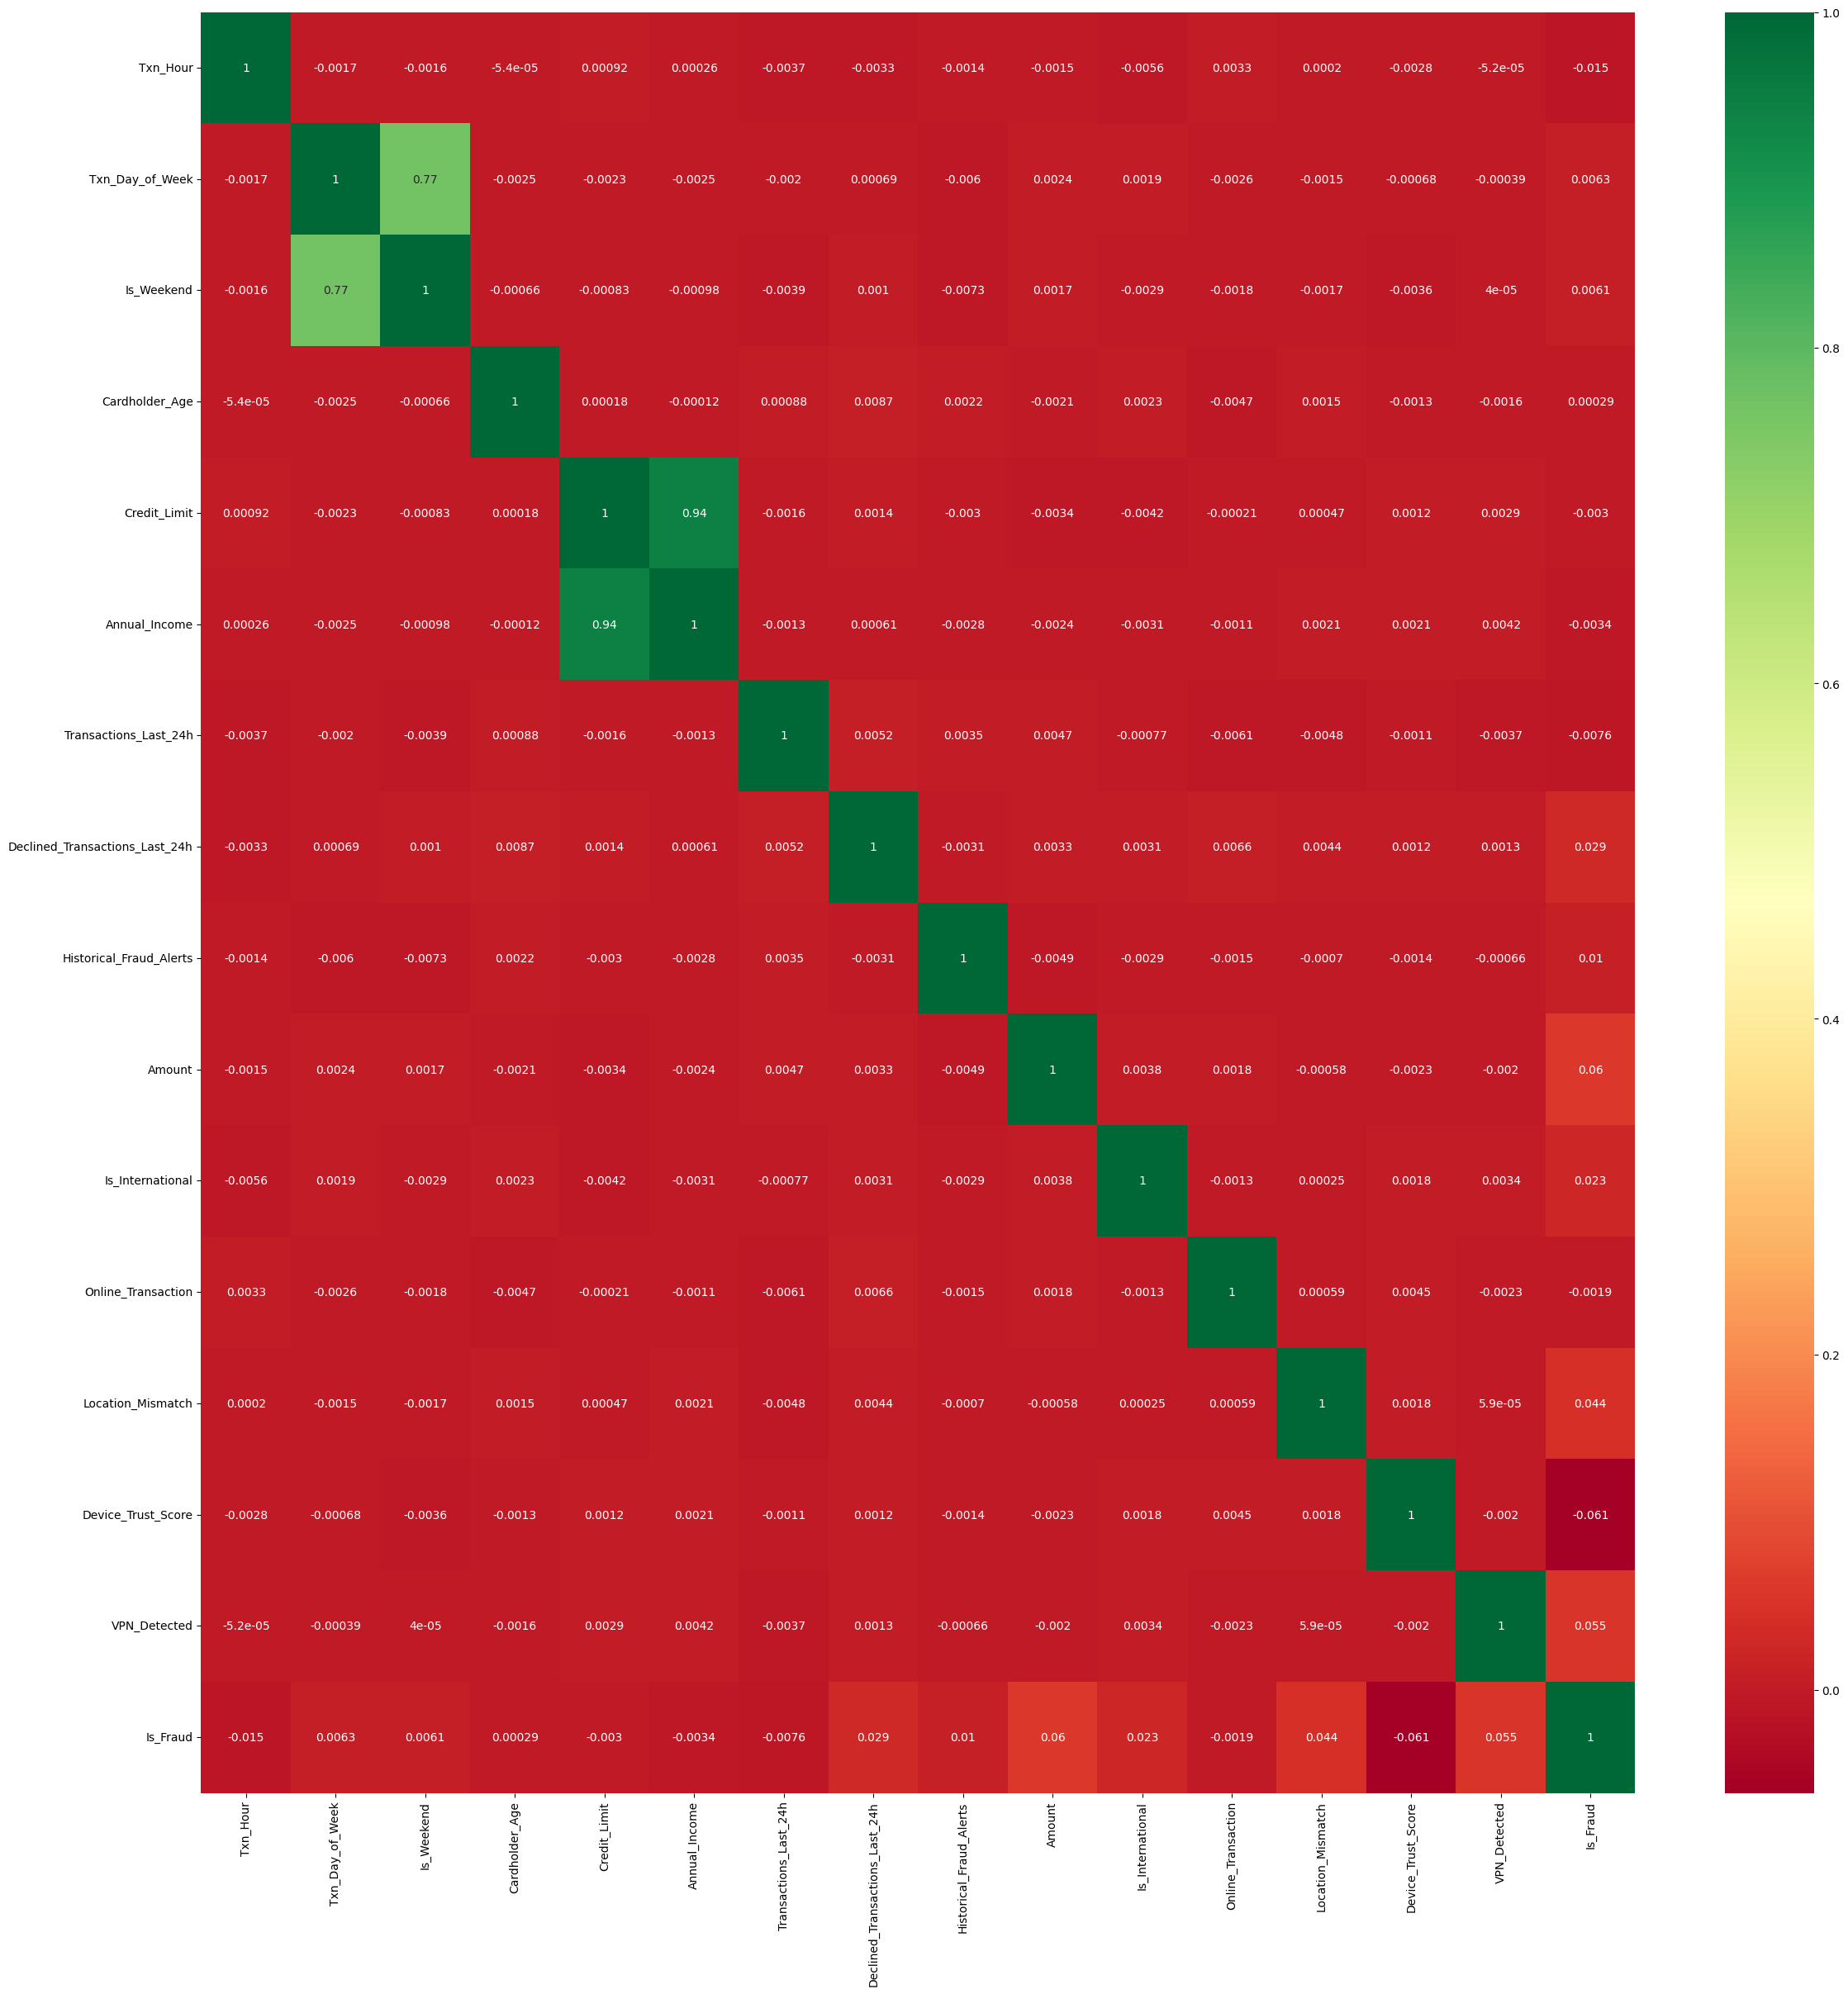

In [ ]:
plt.figure(figsize=(28,28))#increase plot size
sns.heatmap(df.select_dtypes(include=['int', 'float']).corr(),cmap="RdYlGn",annot=True)

In [ ]:
np.where(df.select_dtypes(include=['int', 'float']).corr()>0.9)

(array([ 0,  1,  2,  3,  4,  4,  5,  5,  6,  7,  8,  9, 10, 11, 12, 13, 14,
        15]),
 array([ 0,  1,  2,  3,  4,  5,  4,  5,  6,  7,  8,  9, 10, 11, 12, 13, 14,
        15]))

In [ ]:
df.columns

Index(['Transaction_ID', 'Customer_ID', 'Txn_Hour', 'Txn_Day_of_Week',
       'Is_Weekend', 'Cardholder_Age', 'Card_Type', 'Credit_Limit',
       'Annual_Income', 'Transactions_Last_24h',
       'Declined_Transactions_Last_24h', 'Historical_Fraud_Alerts',
       'Merchant_Category', 'Amount', 'Is_International', 'Online_Transaction',
       'Location_Mismatch', 'Device_Trust_Score', 'VPN_Detected', 'Is_Fraud'],
      dtype='object')

In [ ]:
Transaction_ID	Customer_ID	Txn_Hour	Txn_Day_of_Week	Is_Weekend	Cardholder_Age	Card_Type	Credit_Limit	Annual_Income	Transactions_Last_24h	Declined_Transactions_Last_24h	Historical_Fraud_Alerts	Merchant_Category	Amount	Is_International	Online_Transaction	Location_Mismatch	Device_Trust_Score	VPN_Detected	Is_Fraud

In [ ]:
df.Transaction_ID.value_counts()

,count
Transaction_ID,
TXN_10000000,1
TXN_10000001,1
TXN_10000002,1
TXN_10000003,1
TXN_10000004,1
...,...
TXN_10099995,1
TXN_10099996,1
TXN_10099997,1


In [ ]:
df.Customer_ID.value_counts()

,count
Customer_ID,
CUST_5482,29
CUST_3415,29
CUST_5839,29
CUST_2098,29
CUST_6161,28
...,...
CUST_6939,5
CUST_4434,4
CUST_6199,4


In [ ]:
df.Txn_Hour.value_counts()

,count
Txn_Hour,
5,4271
20,4234
16,4230
3,4225
18,4218
0,4217
19,4207
4,4202
8,4198


In [ ]:
df.Txn_Day_of_Week.value_counts()

,count
Txn_Day_of_Week,
4,16901
3,16626
1,13353
6,13329
0,13292
2,13276
5,13223


In [ ]:
df.Is_Weekend.value_counts()

,count
Is_Weekend,
0,73448
1,26552


In [ ]:
df.Cardholder_Age.value_counts()

,count
Cardholder_Age,
73,1592
67,1566
59,1558
39,1557
42,1549
...,...
75,1432
21,1424
48,1412


In [ ]:
df.Card_Type.value_counts()

,count
Card_Type,
Visa_Classic,40064
Mastercard_Standard,25073
Visa_Gold,14903
Mastercard_Platinum,10036
Amex_Gold,6862
Discover,3062


In [ ]:
df.Credit_Limit.value_counts()

,count
Credit_Limit,
5000,40131
1000,29998
10000,19912
25000,7987
50000,1972


In [ ]:
df.Annual_Income.value_counts()

,count
Annual_Income,
12000,1568
52032,10
17799,9
47115,9
20698,9
...,...
60589,1
29188,1
44665,1


In [ ]:
df.Transactions_Last_24h.value_counts()

,count
Transactions_Last_24h,
3,25511
4,21283
2,20752
5,13281
1,8254
6,6781
7,2769
8,944
9,305


In [ ]:
df.Declined_Transactions_Last_24h.value_counts()

,count
Declined_Transactions_Last_24h,
0,85998
1,12998
2,954
3,50


In [ ]:
df.Historical_Fraud_Alerts.value_counts()

,count
Historical_Fraud_Alerts,
0,94917
1,4033
2,845
3,205


In [ ]:
df.Merchant_Category.value_counts()

,count
Merchant_Category,
grocery,24981
online_shopping,20004
gas_station,15144
restaurants,14955
entertainment,9954
services,6956
travel,5042
luxury_goods,2964


In [ ]:
df.Amount.value_counts()

,count
Amount,
6.52,42
8.65,40
8.24,40
7.16,39
5.50,39
...,...
546.21,1
161.25,1
132.81,1


In [ ]:
df.Is_International.value_counts()

,count
Is_International,
0,94008
1,5992


In [ ]:
df.Online_Transaction.value_counts()

,count
Online_Transaction,
1,54682
0,45318


In [ ]:
df.Location_Mismatch.value_counts()

,count
Location_Mismatch,
0,96946
1,3054


In [ ]:
df.Device_Trust_Score.value_counts()

,count
Device_Trust_Score,
53,1193
98,1190
38,1182
63,1177
54,1170
...,...
99,1041
48,1041
71,1041


In [ ]:
df.	VPN_Detected.value_counts()

,count
VPN_Detected,
0,95979
1,4021


In [ ]:
df.	Is_Fraud.value_counts()

,count
Is_Fraud,
0,99583
1,417


In [ ]:
len(df.columns)

20

In [ ]:
OHE_columns=['Card_Type','Merchant_Category']
standard_scaler=['Cardholder_Age','Credit_Limit','Annual_Income','Amount','Device_Trust_Score',
'Transactions_Last_24h','Declined_Transactions_Last_24h','Historical_Fraud_Alerts']
passthrough=['Txn_Hour','Txn_Day_of_Week','Is_Weekend','Is_International','Online_Transaction','Location_Mismatch','VPN_Detected']

In [ ]:
class ModifiedLabelEncoder(LabelEncoder):
    def fit_transform(self, y, *args, **kwargs):
        return super().fit_transform(y).reshape(-1, 1)

    def transform(self, y, *args, **kwargs):
        return super().transform(y).reshape(-1, 1)

In [ ]:
def same(x):
    return x

In [ ]:
no_trans=FunctionTransformer(same)

In [ ]:
preprocessor = ColumnTransformer([
    ("OHE columns", OneHotEncoder(), OHE_columns),
    ("Standard_scaler", StandardScaler(), standard_scaler),
    ('Pass_through',no_trans,passthrough)])

In [ ]:
preprocessor

ColumnTransformer(transformers=[('OHE columns', OneHotEncoder(),
                                 ['Card_Type', 'Merchant_Category']),
                                ('Standard_scaler', StandardScaler(),
                                 ['Cardholder_Age', 'Credit_Limit',
                                  'Annual_Income', 'Amount',
                                  'Device_Trust_Score', 'Transactions_Last_24h',
                                  'Declined_Transactions_Last_24h',
                                  'Historical_Fraud_Alerts']),
                                ('Pass_through',
                                 FunctionTransformer(func=<function same at 0x79a8b939e020>),
                                 ['Txn_Hour', 'Txn_Day_of_Week', 'Is_Weekend',
                                  'Is_International', 'Online_Transaction',
                                  'Location_Mismatch', 'VPN_Detected'])])

In [ ]:
import pickle

with open("rfpickle.pkl", "wb") as f:
    pickle.dump(preprocessor, f)